# 02 · Workload EDA

CPU distribution, temporal structure, segments, and peaks. All model-relevant statistics (ACF, profiles) use the first 110 points only; the holdout is shaded and never used to choose anything.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") if Path("../challenge_data").exists() else Path(".")
DATA, FIG = ROOT / "challenge_data", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
from statsmodels.tsa.stattools import acf
from cwfc.io import load_metadata, load_readings
from cwfc.targets import build_targets, segment_cpu
from cwfc.split import train_holdout_split

readings = load_readings(DATA)
meta = load_metadata(DATA)
series = build_targets(readings)
train, holdout = train_holdout_split(series, 24)
readings["step"] = readings["timestamp"] // 300
y = series.set_index("timestamp")["aggregate_cpu_utilization"]
y_train = train.set_index("timestamp")["aggregate_cpu_utilization"]

## CPU distribution

count    10000.000
mean         9.388
std         13.019
min          0.007
50%          5.481
90%         19.522
95%         33.280
99%         78.366
max         99.274
Name: avg_cpu, dtype: float64
top 1% of VMs: 0.096  top 10%: 0.436
VMs averaging < 5% CPU: 0.464


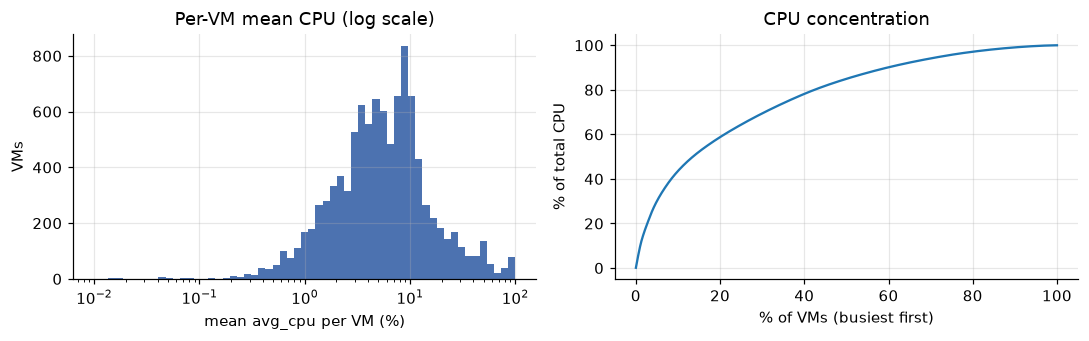

In [2]:
vm_mean = readings.groupby("vm_id")["avg_cpu"].mean()
print(vm_mean.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
ranked = vm_mean.sort_values(ascending=False)
share = ranked.cumsum() / ranked.sum()
print("top 1% of VMs:", round(share.iloc[99], 3), " top 10%:", round(share.iloc[999], 3))
print("VMs averaging < 5% CPU:", round((vm_mean < 5).mean(), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(vm_mean, bins=np.logspace(-2, 2, 60), color="#4c72b0")
axes[0].set_xscale("log"); axes[0].set_xlabel("mean avg_cpu per VM (%)"); axes[0].set_ylabel("VMs")
axes[0].set_title("Per-VM mean CPU (log scale)")
axes[1].plot(np.arange(1, len(share) + 1) / len(share) * 100, share.to_numpy() * 100)
axes[1].set_xlabel("% of VMs (busiest first)"); axes[1].set_ylabel("% of total CPU")
axes[1].set_title("CPU concentration")
fig.tight_layout(); fig.savefig(FIG / "cpu_distribution.png")

The distribution is heavily right-skewed: the median VM averages 5.5% CPU, 46% of VMs stay under 5%, and the busiest 10% produce 44% of the CPU. Most of the fleet is over-provisioned, and aggregate demand depends on a small set of heavy VMs.

In [3]:
pv = readings.pivot(index="step", columns="vm_id", values="avg_cpu")
print("median per-VM std:", round(pv.std().median(), 3), " std of the aggregate:", round(pv.mean(axis=1).std(), 3))
print("per-VM lag-1 autocorrelation:", pv.apply(lambda s: s.autocorr(1)).describe().round(3).to_dict())

median per-VM std: 1.354  std of the aggregate: 0.195


per-VM lag-1 autocorrelation: {'count': 10000.0, 'mean': 0.154, 'std': 0.317, 'min': -0.976, '25%': -0.034, '50%': 0.065, '75%': 0.281, 'max': 0.995}


Single VMs are noisy (median lag-1 autocorrelation 0.07), while the 10,000-VM mean moves by only about ±0.2 points. Averaging cancels most per-VM noise, which makes the aggregate far more forecastable than any one VM.

## Temporal structure

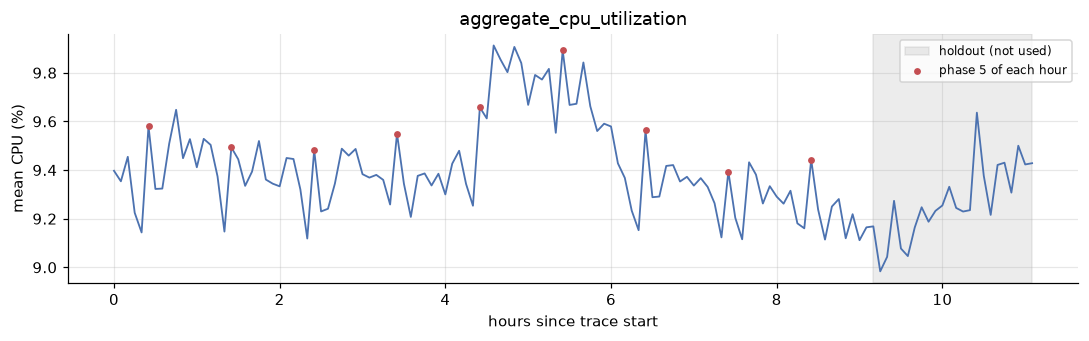

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
hours = y.index / 3600
ax.plot(hours, y.to_numpy(), lw=1.2, color="#4c72b0")
ax.axvspan(hours[len(train)], hours[-1], color="grey", alpha=0.15, label="holdout (not used)")
spikes = [i for i in range(len(y_train)) if i % 12 == 5]
ax.scatter(hours[spikes], y.to_numpy()[spikes], s=12, color="#c44e52", zorder=3, label="phase 5 of each hour")
ax.set_xlabel("hours since trace start"); ax.set_ylabel("mean CPU (%)")
ax.set_title("aggregate_cpu_utilization"); ax.legend(loc="upper right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "aggregate_series.png")

ACF of differences at lag 12 and 24: 0.608 0.576


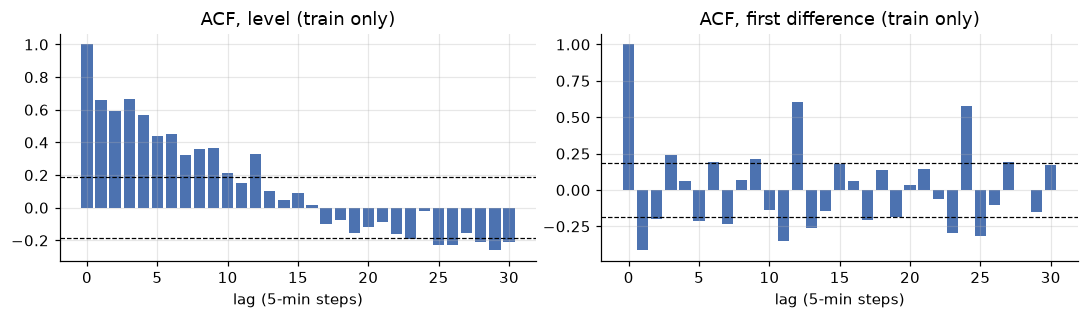

In [5]:
lags = 30
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (title, s) in zip(axes, [("level", y_train), ("first difference", y_train.diff().dropna())]):
    ax.bar(range(lags + 1), acf(s.to_numpy(), nlags=lags), color="#4c72b0")
    ax.axhline(1.96 / np.sqrt(len(s)), ls="--", c="k", lw=0.8); ax.axhline(-1.96 / np.sqrt(len(s)), ls="--", c="k", lw=0.8)
    ax.set_title(f"ACF, {title} (train only)"); ax.set_xlabel("lag (5-min steps)")
fig.tight_layout(); fig.savefig(FIG / "acf.png")
d_acf = acf(y_train.diff().dropna().to_numpy(), nlags=24)
print("ACF of differences at lag 12 and 24:", d_acf[12].round(3), d_acf[24].round(3))

The ACF of the differenced series peaks at lag 12 (0.61) and lag 24 (0.58), so there is an **hourly cycle**. The level ACF decays slowly, which fits a wandering level. With only 11 hours of data I can't see daily or weekly seasonality, so no hour-of-day or weekday features are used.

            mean    std  count
timestamp                     
0         -0.024  0.054      8
1          0.017  0.054      8
2          0.016  0.054      8
3         -0.069  0.076      8
4         -0.206  0.068      8
5          0.136  0.048      8
6         -0.047  0.056      9
7         -0.060  0.131      9
8          0.076  0.075      9
9          0.100  0.063      8
10         0.023  0.071      8
11         0.047  0.046      8


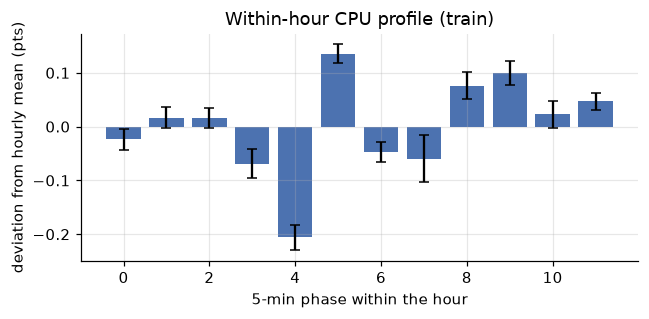

In [6]:
phase = (y_train.index // 300) % 12
detrended = y_train - y_train.rolling(12, center=True).mean()
profile = detrended.groupby(phase).agg(["mean", "std", "count"])
print(profile)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(profile.index, profile["mean"], yerr=profile["std"] / np.sqrt(profile["count"]), color="#4c72b0", capsize=3)
ax.set_xlabel("5-min phase within the hour"); ax.set_ylabel("deviation from hourly mean (pts)")
ax.set_title("Within-hour CPU profile (train)")
fig.tight_layout(); fig.savefig(FIG / "hourly_profile.png")

Each hour has a dip at phase 4 (−0.21 pts) and then a jump at phase 5 (+0.14 pts). That's the shape of scheduled, cron-like jobs starting on a fixed clock offset. The phase is known in advance at any forecast origin, so it is a valid feature, and capacity for it can be pre-scheduled instead of handled reactively.

In [7]:
dev = pv.iloc[:110] - pv.iloc[:110].rolling(12, center=True).mean()
spike = dev[dev.index % 12 == 5].mean()
top = spike.clip(lower=0).sort_values(ascending=False)
print("VMs with a > 1 pt hourly spike:", int((spike > 1).sum()), " > 5 pts:", int((spike > 5).sum()))
print("share of the spike from the top 100 VMs:", round(top.iloc[:100].sum() / spike.sum(), 3))

VMs with a > 1 pt hourly spike: 1627  > 5 pts: 186
share of the spike from the top 100 VMs: 0.804


About 100 VMs produce 80% of the hourly spike. A segment-aware scheduler could stagger those jobs to flatten the peak.

## Segments

                     mean    std     min     max
vm_category                                     
Delay-insensitive   8.236  0.206   7.900   8.878
Interactive        11.493  0.263  10.946  12.149
Unknown            10.233  0.642   9.036  11.561
lag-12 ACF of differences (train): {'Delay-insensitive': np.float64(0.706), 'Interactive': np.float64(0.465), 'Unknown': np.float64(0.525)}


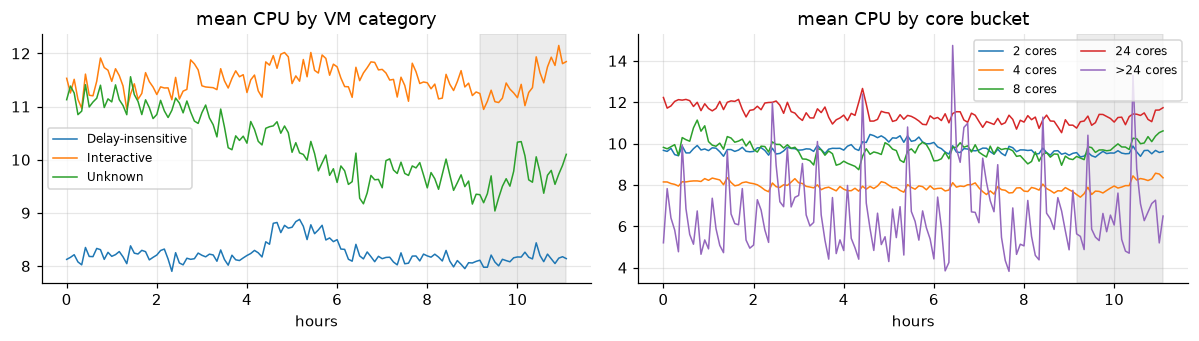

In [8]:
cat = segment_cpu(readings, meta, "vm_category")
cores = segment_cpu(readings, meta, "virtual_core_bucket")[["2", "4", "8", "24", ">24"]]
print(cat.describe().T[["mean", "std", "min", "max"]])
print("lag-12 ACF of differences (train):", {c: round(cat[c].iloc[:110].diff().autocorr(12), 3) for c in cat})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for col in cat:
    axes[0].plot(cat.index / 3600, cat[col], label=col, lw=1)
axes[0].set_title("mean CPU by VM category"); axes[0].set_xlabel("hours"); axes[0].legend(fontsize=8)
for col in cores:
    axes[1].plot(cores.index / 3600, cores[col], label=f"{col} cores", lw=1)
axes[1].set_title("mean CPU by core bucket"); axes[1].set_xlabel("hours"); axes[1].legend(fontsize=8, ncol=2)
for ax in axes:
    ax.axvspan(series["timestamp"].iloc[len(train)] / 3600, series["timestamp"].iloc[-1] / 3600, color="grey", alpha=0.15)
fig.tight_layout(); fig.savefig(FIG / "segments.png")

Interactive VMs run hotter (11.5%) than delay-insensitive ones (8.2%). `Unknown` VMs are the most volatile, falling from about 11% to 9–10% over the window. The `>24` core bucket has only 10 VMs and is mostly noise. Each segment carries the hourly cycle, which is strongest in delay-insensitive VMs (highest lag-12 ACF of differences), the category expected to run batch jobs.

In [9]:
base = cat.iloc[40:50].mean()
weights = meta["vm_category"].value_counts(normalize=True)
shift = (cat.iloc[53:72].mean() - base) * weights
print("contribution to the hours 4.4-6 bump (pts of aggregate):")
print(shift.round(3))

contribution to the hours 4.4-6 bump (pts of aggregate):
vm_category
Delay-insensitive    0.314
Interactive          0.086
Unknown             -0.016
dtype: float64


The biggest train-window excursion, a roughly 0.5 pt bump between hours 4.4 and 6, comes almost entirely from delay-insensitive VMs. Batch work arriving as a block like this is the hardest pattern for a short-history model, and the backtest's worst folds fall at its edges.

## Peaks, lows and the capacity view

In [10]:
threshold = y_train.quantile(0.8)
print("train peak threshold (80th pct):", round(threshold, 3))
print("peak timestamps in train:", int((y_train >= threshold).sum()), " in holdout:", int((holdout['aggregate_cpu_utilization'] >= threshold).sum()))
print("highest:", y.idxmax() / 3600, "h", round(y.max(), 3), "  lowest:", y.idxmin() / 3600, "h", round(y.min(), 3))
p95 = readings.groupby("timestamp")["avg_cpu"].quantile(0.95)
core_n = meta.set_index("vm_id")["virtual_core_bucket"].replace({">24": "32"}).astype(float)
readings["cores"] = readings["vm_id"].map(core_n)
busy = readings.groupby("timestamp").apply(lambda g: (g["avg_cpu"] / 100 * g["cores"]).sum(), include_groups=False)
print("p95 VM CPU per timestamp:", p95.describe()[["mean", "min", "max"]].round(2).to_dict())
print("busy vCPUs:", busy.describe()[["mean", "min", "max"]].round(0).to_dict(), "of", int(core_n.sum()), "allocated")

train peak threshold (80th pct): 9.554
peak timestamps in train: 22  in holdout: 1
highest: 4.583333333333333 h 9.912   lowest: 9.25 h 8.984


p95 VM CPU per timestamp: {'mean': 37.32, 'min': 34.14, 'max': 41.17}
busy vCPUs: {'mean': 2638.0, 'min': 2518.0, 'max': 2753.0} of 28396 allocated


Peaks are mild: the highest 5-minute value is only 5.6% above the series mean. Measured in cores, the fleet keeps roughly 2,500–2,750 of its ~28,400 allocated vCPUs busy (`>24` counted as 32). The p95 VM runs at about 37%. The operational risk is sudden batch bumps of around 0.5 pts (≈150 vCPUs) and the hourly spike, not sustained overload.